# TuniShop — Machine learning 01. Préparation des jeux de données

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Préparer, **séparément de l'EDA**, les jeux de données des 4 cas de machine learning, et vérifier pour chacun les 5 conditions d'un modèle fiable :

| Vérification | Question | Risque si on l'oublie |
|---|---|---|
| 1. Cible | La cible est-elle bien définie ? Quel est son taux ? | modèle qui apprend autre chose que la question posée |
| 2. Variables | Quelles variables, connues à quel moment ? | variable indisponible au moment de prédire |
| 3. Fuites | Aucune information de l'avenir dans les variables ? | modèle excellent en test, inutile en réalité |
| 4. Valeurs manquantes | Combien, et quel traitement ? | erreurs ou biais silencieux |
| 5. Dérive | Les variables de 2025 ressemblent-elles à celles de 2023-2024 ? | performance qui chute en production |

| Cas | Table source | Notebook de modélisation |
|---|---|---|
| Prévision des ventes | `produits_mois` agrégée par catégorie | `02_Prevision_Ventes` |
| Churn | `clients` + `segments_rfm` + `clusters_clients` | `03_Prediction_Churn` |
| Demande | `produits_mois` | `04_Prediction_Demande` |
| Retard de livraison (ajouté) | `expeditions` | `06_Prediction_Retard_Livraison` |

**Produit :** 4 jeux de données dans `05_Data/features` (`ml_ventes`, `ml_churn`, `ml_demande`, `ml_retard`), chacun avec une colonne `periode` (apprentissage / test). Les listes de variables sont dans `features.CAS_ML` : tous les notebooks utilisent exactement les mêmes.

**Ordre d'exécution de la phase :** 01 → 02, 03, 04, 06 (dans n'importe quel ordre) → 05_Evaluation_Modeles.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

# True = reconstruire les tables depuis les vues du DWH avant de préparer les jeux de données
RECONSTRUIRE = False

## 1. Données sources et contrôle 🔗 SQL direct

Les tables viennent de `05_Data/features` (construites par `01_EDA_Global` à partir des vues `bi`). Trois requêtes exécutées par SQL Server vérifient qu'elles correspondent toujours au DWH.

In [2]:
chargement.ouvrir_connexion()
if RECONSTRUIRE:
    vues, p = chargement.charger_donnees(source="dwh")
    for nom, table in {"clients": features.table_clients(p), "produits_mois": features.table_produits_mois(p, vues),
                       "expeditions": features.table_expeditions(p, vues)}.items():
        features.sauvegarder(table, nom)

clients = features.lire("clients")
produits_mois = features.lire("produits_mois")
expeditions = features.lire("expeditions")

cle = lambda d: int(pd.Timestamp(d).strftime("%Y%m%d"))
# (a) CA TTC des lignes abouties par année (base des cas ventes et demande)
ca_sql = sql("""
    SELECT d.annee, SUM(v.montant_ttc) AS ca_ttc, SUM(v.quantite) AS quantite
    FROM bi.v_fact_ventes v
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = v.statut_commande_sk
    JOIN bi.v_dim_date d            ON d.date_sk = v.date_commande_sk
    WHERE s.famille_statut = 'aboutie' AND v.produit_sk > 0
    GROUP BY d.annee
""").set_index("annee").sort_index()
ca_tab = produits_mois.groupby(produits_mois["mois"].dt.year)[["ca_ttc", "quantite"]].sum()
# (b) expéditions livrées et taux de retard par année d'expédition (cas retard)
ret_sql = sql("""
    SELECT d.annee, COUNT(*) AS expeditions_livrees,
           1.0 * SUM(CASE WHEN l.retard_j > 0 THEN 1 ELSE 0 END) / COUNT(*) AS taux_retard
    FROM bi.v_fact_livraisons l
    JOIN bi.v_dim_date d ON d.date_sk = l.date_expedition_sk
    WHERE l.est_livree = 1 AND l.date_expedition_sk > 0
    GROUP BY d.annee
""").set_index("annee").sort_index()
ret_tab = expeditions.groupby(expeditions["date_expedition"].dt.year)["en_retard"].agg(["size", "mean"])
# (c) clients actifs au 30/09/2024 (cas churn)
d = temporal_split.DATES_OBS_APPRENTISSAGE[-1]
actifs_sql = chargement.valeur("""
    SELECT COUNT(DISTINCT c.client_sk) FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue' AND c.date_commande_sk BETWEEN ? AND ?""",
    [cle(d - pd.Timedelta(days=temporal_split.FENETRE_ACTIVITE_J)), cle(d)])

controles = pd.DataFrame([
    {"contrôle": f"CA TTC lignes abouties {a}", "SQL (vues bi)": ca_sql.loc[a, "ca_ttc"], "table": ca_tab.loc[a, "ca_ttc"]} for a in ca_sql.index
] + [
    {"contrôle": f"expéditions livrées {a}", "SQL (vues bi)": ret_sql.loc[a, "expeditions_livrees"], "table": ret_tab.loc[a, "size"]} for a in ret_sql.index
] + [{"contrôle": f"clients actifs au {d.date()}", "SQL (vues bi)": actifs_sql, "table": (clients["date_observation"] == d).sum()}])
controles["statut"] = np.where((controles["SQL (vues bi)"].astype(float) - controles["table"].astype(float)).abs() < 0.01, "OK", "ÉCART")
controles

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)


,contrôle,SQL (vues bi),table,statut
0,CA TTC lignes abouties 2023,3 358 371.900,3 358 371.900,OK
1,CA TTC lignes abouties 2024,4 970 448.600,4 970 448.600,OK
2,CA TTC lignes abouties 2025,7 068 897.400,7 068 897.400,OK
3,expéditions livrées 2023,13 275.000,13 275.000,OK
4,expéditions livrées 2024,18 911.000,18 911.000,OK
5,expéditions livrées 2025,26 590.000,26 590.000,OK
6,clients actifs au 2024-09-30,5 109.000,5 109.000,OK


> **Lecture.** Les **7 contrôles** sont identiques entre SQL Server et les tables : CA TTC des lignes abouties (3 358 372, 4 970 449 et 7 068 897 DT), expéditions livrées (13 275, 18 911 et 26 590) et clients actifs au 30/09/2024 (5 109). Les jeux de données du ML reposent donc sur le DWH validé.

## 2. Construction des 4 jeux de données

- **ventes** : le CA TTC par catégorie et par mois, avec la tendance `t` (mois écoulés depuis janvier 2023) et le **calendrier commercial** du mois (part des jours de Ramadan, de pré-Aïd, de Black Friday, de soldes...), connu à l'avance dans `v_dim_date` ;
- **churn** : la table `clients` + le segment RFM et le groupe k-means du data mining + un indicateur « a donné un avis » ;
- **demande** : chaque mois d'une année est prévu depuis le 31 décembre de l'année précédente (horizon 1 à 12 mois) : les variables d'historique ne regardent que **l'année civile précédente** ;
- **retard** : la table `expeditions` telle quelle (variables connues le jour de l'expédition).

In [3]:
jeux = {
    "ventes": features.dataset_ventes(produits_mois),
    "churn": features.dataset_churn(clients),
    "demande": features.dataset_demande(produits_mois),
    "retard": expeditions.copy(),
}
fiche = pd.DataFrame([{
    "cas": cas, "titre": features.CAS_ML[cas]["titre"], "type": features.CAS_ML[cas]["type"], "grain": features.CAS_ML[cas]["grain"],
    "cible": features.CAS_ML[cas]["cible"], "lignes apprentissage": int((t["periode"] == "apprentissage").sum()),
    "lignes test": int((t["periode"] == "test").sum()), "variables numériques": len(features.CAS_ML[cas]["numeriques"]),
    "variables catégorielles": len(features.CAS_ML[cas]["categorielles"])} for cas, t in jeux.items()])
fiche

,cas,titre,type,grain,cible,lignes apprentissage,lignes test,variables numériques,variables catégorielles
0,ventes,Prévision des ventes (CA TTC mensuel par catég...,régression (série temporelle),1 catégorie x 1 mois,ca_ttc,216,108,9,1
1,churn,Prédiction du churn à 90 jours,classification binaire,1 client actif x 1 fin de trimestre,churn,24074,19414,23,7
2,demande,Prédiction de la demande (quantité mensuelle p...,régression (comptage),1 produit x 1 mois,quantite,6223,6992,17,2
3,retard,Prédiction du retard de livraison,classification binaire,1 expédition livrée,en_retard,32186,26590,8,7


## 3. Les cibles

Pour les classifications (churn, retard) on regarde le **taux** de la cible, pour les régressions (ventes, demande) son **niveau** et sa **distribution**. On compare apprentissage et test : une cible qui change entre les deux périodes rendra l'évaluation plus exigeante.

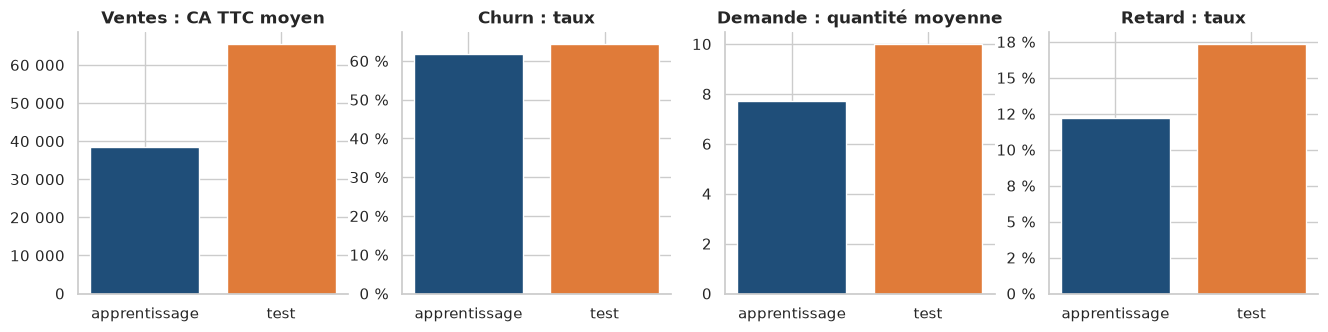

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml01_cibles                                   8 lignes


,cas,cible,periode,lignes,moyenne,mediane,part_de_zero
0,ventes,ca_ttc,apprentissage,216,38 559.354,22 189.550,0.000
1,ventes,ca_ttc,test,108,65 452.754,38 653.850,0.000
2,churn,churn,apprentissage,24074,0.617,1.000,0.383
3,churn,churn,test,19414,0.643,1.000,0.357
4,demande,quantite,apprentissage,6223,7.735,3.000,0.199
5,demande,quantite,test,6992,9.994,4.000,0.187
6,retard,en_retard,apprentissage,32186,0.122,0.000,0.878
7,retard,en_retard,test,26590,0.173,0.000,0.827


In [4]:
cibles = []
for cas, t in jeux.items():
    y = features.CAS_ML[cas]["cible"]
    for periode, g in t.groupby("periode"):
        cibles.append({"cas": cas, "cible": y, "periode": periode, "lignes": len(g), "moyenne": g[y].mean(),
                       "mediane": g[y].median(), "part_de_zero": (g[y] == 0).mean()})
cibles = pd.DataFrame(cibles)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, cas in zip(axes, jeux):
    c = cibles[cibles["cas"] == cas].set_index("periode")["moyenne"]
    ax.bar(c.index, c.values, color=[cfg.BLEU, cfg.ORANGE])
    ax.set_title({"ventes": "Ventes : CA TTC moyen", "churn": "Churn : taux", "demande": "Demande : quantité moyenne",
                  "retard": "Retard : taux"}[cas])
    if cas in ("churn", "retard"): cfg.format_pourcent(ax)
    else: cfg.format_milliers(ax)
montrer("ML01_1_cibles")
cfg.exporter_table(cibles, "ML01_cibles", index=False)
cibles

> **Lecture.** Les 4 cibles **augmentent** entre l'apprentissage et le test : le CA moyen d'une catégorie par mois passe de 38 600 à 65 500 DT (croissance), la quantité moyenne d'un produit par mois de 7,7 à 10,0 unités, le churn de 61,7 % à 64,3 %, et surtout le retard de **12,2 % à 17,3 %**. Pour la demande, 19 % des couples produit × mois sont à zéro : la MAPE est inutilisable, on mesurera le WAPE. Pour le churn, les classes sont peu déséquilibrées (64 % de positifs) : pas de rééquilibrage nécessaire, mais l'exactitude serait trompeuse (on suivra l'AUC).

## 4. Les fuites de données

Une **fuite** est une variable qui contient (directement ou non) la réponse, ou une information connue seulement **après** le moment de la prédiction. On vérifie que les colonnes écartées ne figurent dans aucune liste de variables.

In [5]:
fuites = []
for cas, conf in features.CAS_ML.items():
    variables = set(features.colonnes_ml(cas))
    for colonnes, raison in conf["ecartees"].items():
        presentes = [c.strip() for c in colonnes.split("/") if c.strip() in variables]
        fuites.append({"cas": cas, "colonnes écartées": colonnes, "raison": raison,
                       "statut": "OK" if not presentes else "ÉCART : " + ", ".join(presentes)})
    assert conf["cible"] not in variables, f"la cible de {cas} est dans ses propres variables !"
fuites = pd.DataFrame(fuites)
cfg.exporter_table(fuites, "ML01_fuites", index=False)
fuites

  ✔ ana.ml01_fuites                                  11 lignes


,cas,colonnes écartées,raison,statut
0,ventes,quantite / nb_commandes,mesurés en même temps que la cible (fuite),OK
1,churn,segment_fidelite,attribut calculé par le métier sur tout l'hist...,OK
2,churn,date_fin_validite / est_courant,"décrivent l'état final du client, inconnu à la...",OK
3,churn,client_sk / date_observation,identifiants (pas des comportements),OK
4,demande,ca_ttc / ca_ht / marge_ht / nb_commandes,mesurés en même temps que la cible (fuite),OK
5,demande,stock_fin_mois / en_rupture du mois,connus seulement à la fin du mois prévu (fuite),OK
6,retard,date_livraison_sk / delai_livraison_j / retard_j,c'est la réponse elle-même,OK
7,retard,est_livree_a_temps / statut_livraison,issue de la livraison,OK
8,retard,nb_tentatives / est_premiere_tentative,connues pendant la livraison,OK
9,retard,cout_transport_ht,facturé après coup (peut dépendre des tentatives),OK


> **Lecture.** Les **11 groupes de colonnes écartées** (identifiants, réponse elle-même, informations connues après la date de prédiction) sont absents de toutes les listes de variables, et aucune cible n'est dans ses propres variables. Pour la demande, deux pièges sont évités : le stock et la rupture du mois à prévoir (connus seulement à la fin du mois), et le CA du mois (mesuré en même temps que la quantité).

## 5. Valeurs manquantes et traitement prévu

Le traitement est **appris sur l'apprentissage** dans le pipeline scikit-learn (`features.preprocesseur`) : médiane pour une variable numérique, modalité « inconnu » pour une catégorielle. On liste ici les vides et leur raison.

In [6]:
raisons = {
    "note_moyenne": "client sans avis -> la variable a_donne_avis porte l'information",
    "retard_max_j": "aucune livraison reçue à la date d'observation",
    "part_livraisons_retard": "aucune livraison reçue à la date d'observation",
    "tranche_age": "clients professionnels (pas d'âge)",
    "moy_3_derniers_mois": "produit non vendu en fin d'année précédente",
    "meme_mois_annee_prec": "produit pas encore vendu ce mois-là l'année précédente",
    "moy_annee_prec": "produit nouveau (indicateur nouveau_produit)",
    "part_rupture_annee_prec": "produit nouveau",
    "delai_preparation_h": "rares colis sans temps de préparation",
}
vides = []
for cas, t in jeux.items():
    app = t[t["periode"] == "apprentissage"]
    for c in features.colonnes_ml(cas):
        part = app[c].isna().mean()
        if part > 0:
            vides.append({"cas": cas, "variable": c, "part_vide_apprentissage": part,
                          "traitement": "médiane" if c in features.CAS_ML[cas]["numeriques"] else "modalité « inconnu »",
                          "raison": raisons.get(c, "")})
vides = pd.DataFrame(vides).sort_values(["cas", "part_vide_apprentissage"], ascending=[True, False])
cfg.exporter_table(vides, "ML01_valeurs_manquantes", index=False)
vides

  ✔ ana.ml01_valeurs_manquantes                       9 lignes


,cas,variable,part_vide_apprentissage,traitement,raison
2,churn,note_moyenne,0.624,médiane,client sans avis -> la variable a_donne_avis p...
0,churn,part_livraisons_retard,0.048,médiane,aucune livraison reçue à la date d'observation
1,churn,retard_max_j,0.048,médiane,aucune livraison reçue à la date d'observation
3,churn,tranche_age,0.032,modalité « inconnu »,clients professionnels (pas d'âge)
4,churn,genre,0.001,modalité « inconnu »,
7,demande,meme_mois_annee_prec,0.174,médiane,produit pas encore vendu ce mois-là l'année pr...
5,demande,moy_annee_prec,0.084,médiane,produit nouveau (indicateur nouveau_produit)
6,demande,moy_3_derniers_mois,0.084,médiane,produit non vendu en fin d'année précédente
8,demande,part_rupture_annee_prec,0.084,médiane,produit nouveau


> **Lecture.** Le vide le plus important est la **note moyenne** (62 % des photos de clients) : la variable `a_donne_avis` garde l'information « n'a jamais donné d'avis », et la médiane complète la note. Pour la demande, 8 % des lignes concernent des produits sans historique l'année précédente (`nouveau_produit` = 1) et 17 % des mois n'ont pas de vente l'an dernier le même mois. Tous ces remplacements sont appris sur l'apprentissage uniquement, dans le pipeline.

## 6. Dérive entre l'apprentissage et le test (PSI)

L'**indice de stabilité de population (PSI)** compare la distribution d'une variable en 2023-2024 et en 2025 : moins de 0,10 = stable ; 0,10 à 0,25 = dérive modérée ; plus de 0,25 = forte dérive.

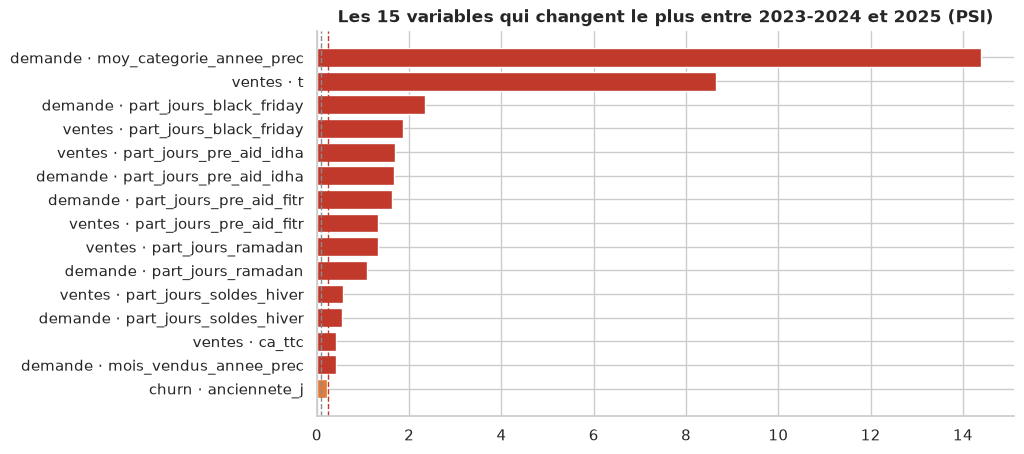

  ✔ ana.ml01_derive                                  78 lignes


niveau,stable,dérive modérée,forte dérive
cas,,,
churn,27,4,0
demande,12,1,7
retard,16,0,0
ventes,4,0,7


In [7]:
derives = []
for cas, t in jeux.items():
    app, test = t[t["periode"] == "apprentissage"], t[t["periode"] == "test"]
    d = validation.derive(app, test, features.colonnes_ml(cas) + [features.CAS_ML[cas]["cible"]])
    d.insert(0, "cas", cas)
    derives.append(d)
derives = pd.concat(derives, ignore_index=True)

top = derives.sort_values("psi", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["cas"] + " · " + top["variable"], top["psi"],
        color=[cfg.ROUGE if v > 0.25 else (cfg.ORANGE if v > 0.10 else cfg.BLEU) for v in top["psi"]])
ax.axvline(0.10, color=cfg.GRIS, ls="--", lw=1); ax.axvline(0.25, color=cfg.ROUGE, ls="--", lw=1)
ax.set_title("Les 15 variables qui changent le plus entre 2023-2024 et 2025 (PSI)")
montrer("ML01_2_derive")
cfg.exporter_table(derives, "ML01_derive", index=False)
derives.groupby(["cas", "niveau"], observed=True).size().unstack(fill_value=0)

> **Lecture.** Trois situations très différentes. **Churn** : 27 variables stables et 4 en dérive modérée (ancienneté, pire retard subi, canal d'inscription, part mobile : l'historique des clients s'allonge et le mobile progresse). **Ventes et demande** : la tendance `t` et les parts de calendrier dérivent fortement, mais c'est **voulu** : la tendance avance par construction et le Ramadan et l'Aïd changent de mois chaque année ; c'est justement ce que le modèle doit extrapoler. **Retard** : les 16 variables sont **toutes stables**, alors que le taux de retard passe de 12 % à 17 % : ce n'est pas la population qui change, c'est la **relation** entre les variables et le retard (SahelLog se dégrade). Ce type de dérive est le plus difficile, car il est invisible dans les variables.

## 7. Variables très corrélées (churn)

Pour la **régression logistique**, deux variables qui portent la même information rendent les coefficients instables. On repère les paires avec une corrélation de Spearman supérieure à 0,8 (les modèles d'arbres y sont peu sensibles).

In [8]:
app = jeux["churn"][jeux["churn"]["periode"] == "apprentissage"]
corr = app[features.CAS_ML["churn"]["numeriques"]].corr(method="spearman")
paires = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r").reset_index()
          .query("abs(r) > 0.8").sort_values("r", ascending=False))
paires

,level_0,level_1,r
67,frequence,score_f,0.993
91,montant_reconnu_ttc,score_m,0.980
433,a_donne_avis,nb_avis,0.975
337,part_livraisons_retard,retard_max_j,0.968
59,frequence,nb_livraisons,0.965
320,nb_livraisons,score_f,0.958
58,frequence,nb_categories,0.880
297,nb_categories,score_f,0.873
289,nb_categories,nb_livraisons,0.847
273,nb_commandes_90j,score_r,0.844


> **Lecture.** Plusieurs paires portent la même information : les scores RFM et leurs variables d'origine (fréquence / score F : 0,99 ; montant / score M : 0,98 ; récence / score R : -0,98), avoir donné un avis et nombre d'avis (0,98), part de livraisons en retard et pire retard (0,97). **Conséquence :** la régression logistique sera régularisée (paramètre C) pour rester stable ; les modèles d'arbres n'en souffrent pas.

## 8. Sauvegarde des jeux de données

In [9]:
for cas, t in jeux.items():
    colonnes = ([c for c in ["client_sk", "date_observation", "produit_id", "mois", "livraison_id", "date_expedition"] if c in t.columns]
                + features.colonnes_ml(cas) + [features.CAS_ML[cas]["cible"], "periode"])
    features.sauvegarder(t[list(dict.fromkeys(colonnes))], f"ml_{cas}")
cfg.exporter_table(fiche, "ML01_fiche_jeux_de_donnees", index=False)

  ml_ventes                   324 lignes x 13 colonnes -> ml_ventes.parquet
  ml_churn                 43 488 lignes x 34 colonnes -> ml_churn.parquet
  ml_demande               13 215 lignes x 23 colonnes -> ml_demande.parquet
  ml_retard                58 776 lignes x 19 colonnes -> ml_retard.parquet


  ✔ ana.ml01_fiche_jeux_de_donnees                    4 lignes


WindowsPath('C:/Users/Abdeljaouad/Desktop/Projet TuniShop/3-Développement/4-Projet Final Complet/5-Analyse_ML/6-Projet Final Analyses et ML/06_Exports/Tables/ML01_fiche_jeux_de_donnees.csv')

## 9. Synthèse

> **Lecture.** Les 4 jeux de données sont prêts et contrôlés contre le DWH : **324** lignes pour les ventes (9 catégories × 36 mois), **43 488** photos de clients pour le churn, **13 215** couples produit × mois pour la demande (2024 et 2025, avec l'historique de l'année précédente), **58 776** expéditions pour le retard. Aucune fuite, des vides expliqués et traités dans le pipeline. Point de vigilance majeur : la **dérive du retard**, invisible dans les variables, qui pèsera sur ce modèle en 2025.

In [10]:
chargement.fermer_connexion()

Connexion fermée.
